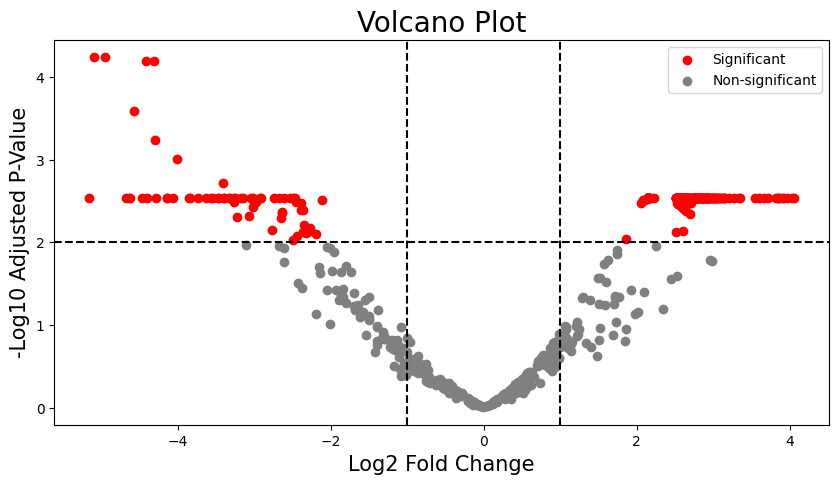

In [12]:
# Import necessary libraries
import matplotlib.pyplot as plt  # Used for creating plots and visualizations
import numpy as np  # Used for numerical computations
import pandas as pd  # Used for handling and manipulating data in tabular form

# Load the data from the TSV (tab-separated values) file into a pandas DataFrame.
# A DataFrame is a table-like data structure with rows and columns, similar to a spreadsheet.
# sep='\t' indicates that the columns in our file are separated by tabs.
# header=0 indicates that the first line (0-indexed) in the file contains the column headers.
df = pd.read_csv('GSE93300.top.table.tsv', sep='\t', header=0)

# Identify rows (i.e., genes) in the DataFrame where the adjusted p-value is less than 0.01 and
# the absolute log2 fold change is greater than 1.
# These genes are considered significantly differentially expressed.
# abs(df['logFC']) returns a Series with the absolute value of the log2 fold change for each gene.
sig = df.loc[(df['adj.P.Val'] < 0.01) & (abs(df['logFC']) > 1)]

# Identify rows in the DataFrame that were not marked as significant in the previous step.
# ~df.index.isin(sig.index) creates a boolean mask where rows that are in sig are marked as False.
# We select the rows in df where the mask is True, i.e., the rows not in sig.
non_sig = df.loc[~df.index.isin(sig.index)]

# Create a new figure for the plot with a specific size (10 units wide by 5 units tall).
plt.figure(figsize=(10, 5))

# Create a scatter plot for the significantly differentially expressed genes.
# The x-coordinate is the log2 fold change, and the y-coordinate is the negative log10 adjusted p-value.
# The points are colored red and labeled as 'Significant'.
plt.scatter(sig['logFC'], -np.log10(sig['adj.P.Val']), color='red', label='Significant')

# Do the same for the non-significantly differentially expressed genes, but color the points grey and label them 'Non-significant'.
plt.scatter(non_sig['logFC'], -np.log10(non_sig['adj.P.Val']), color='grey', label='Non-significant')

# Add a horizontal line at the negative log10 of the adjusted p-value threshold (0.01).
# This line helps visualize the cut-off for significance based on adjusted p-value.
plt.axhline(y=-np.log10(0.01), color='black', linestyle='--')

# Add vertical lines at the log2 fold change thresholds (-1 and 1).
# These lines help visualize the cut-off for significance based on fold change.
plt.axvline(x=-1, color='black', linestyle='--')
plt.axvline(x=1, color='black', linestyle='--')

# Set the labels for the x-axis and y-axis, and the title for the plot.
plt.xlabel('Log2 Fold Change', fontsize=15)
plt.ylabel('-Log10 Adjusted P-Value', fontsize=15)
plt.title('Volcano Plot', fontsize=20)

# Display a legend that maps the color of the points to their labels ('Significant' and 'Non-significant').
plt.legend(loc='best')

# Display the plot.
plt.show()


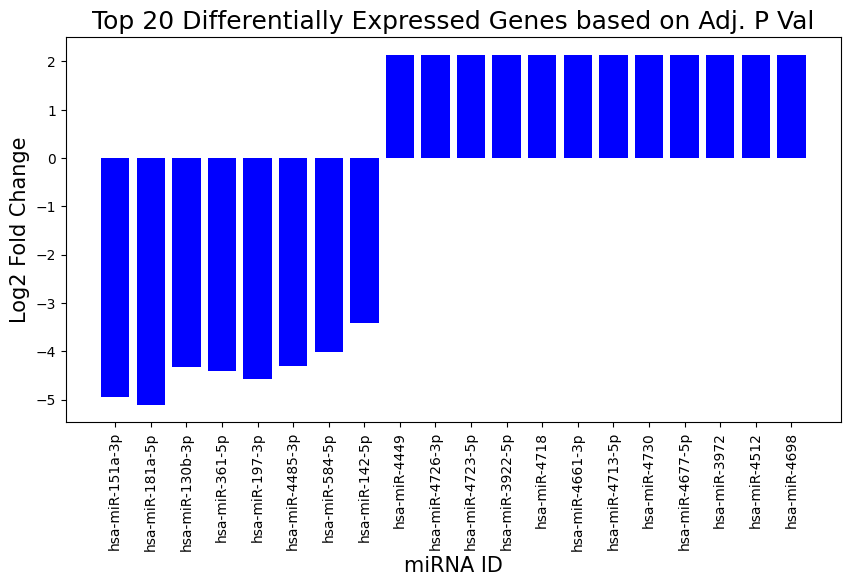

In [18]:
# This line sorts the dataframe 'df' by the 'adj.P.Val' column in ascending order.
# This means that rows with smaller 'adj.P.Val' values (i.e., more statistically significant genes) will come first.
# The sorted dataframe is then stored in a new dataframe 'df_sorted'.
df_sorted = df.sort_values(by='adj.P.Val', ascending=True)

# The 'head' function returns the first n rows of a dataframe. Here, we're taking the first 20 rows.
# Because 'df_sorted' is sorted by 'adj.P.Val', these are the 20 most statistically significant genes.
# This new subset of the dataframe is stored in 'top_genes'.
top_genes = df_sorted.head(20)

# 'plt.figure' is used to create a new figure for plotting. The 'figsize' argument is used to set the size of the figure.
# Here, we're making a figure that's 10 units wide and 5 units tall.
plt.figure(figsize=(10,5))

# 'plt.bar' creates a bar plot. It takes two arguments: the x values and the y values for the bars.
# We're using 'miRNA_ID' for the x values (the labels on the bars) and 'logFC' for the y values (the height of the bars).
# We're also setting the color of the bars to blue.
plt.bar(top_genes['miRNA_ID'], top_genes['logFC'], color='blue')

# 'plt.xlabel' and 'plt.ylabel' are used to set the labels for the x and y axes. Here, we're labeling them 'miRNA ID' and 'Log2 Fold Change'.
plt.xlabel('miRNA ID', fontsize=15)
plt.ylabel('Log2 Fold Change', fontsize=15)

# 'plt.xticks' is used to modify the x-axis ticks. The 'rotation' argument rotates the tick labels by a certain angle.
# Here, we're rotating the x-axis tick labels by 90 degrees to make them vertical. This is done to prevent overlapping of labels.
plt.xticks(rotation=90)

# 'plt.title' is used to set the title of the plot.
plt.title('Top 20 Differentially Expressed Genes based on Adj. P Val', fontsize=18)

# Finally, 'plt.show()' is used to display the plot. Without this line, the plot would be created internally but not displayed.
plt.show()
